Week 3 Task: Advanced Data Analysis and Visualization in Logistics

Librarys

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DataSet

In [15]:
df = pd.read_csv("/content/drive/MyDrive/CSV/week3_hypothetical_logistics_dataset.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (240, 10)


,shipment_id,order_date,region,transport_mode,distance_km,shipment_volume_units,delivery_time_days,promised_delivery_days,transport_cost_inr,on_time_delivery
0,SHP0001,2026-01-31,North,Rail,372.3,53,3.0,3.6,2729.52,1
1,SHP0002,2026-02-01,East,Air,413.1,123,1.9,1.5,6726.17,0
2,SHP0003,2026-01-16,South,Air,438.3,111,0.5,1.0,6924.52,1
3,SHP0004,2026-01-27,South,Road,367.4,206,2.5,2.6,4031.63,1
4,SHP0005,2026-05-22,South,Road,557.1,66,6.8,6.0,4500.80,0


Dataset Overview

In [16]:
df["order_date"] = pd.to_datetime(df["order_date"])

In [17]:
print("Rows and Columns:", df.shape)

Rows and Columns: (240, 10)


Data quality checking

In [18]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print(
    "Duplicate shipment IDs:",
    df["shipment_id"].duplicated().sum()
)

display(df.describe())

Missing values:
shipment_id               0
order_date                0
region                    0
transport_mode            0
distance_km               0
shipment_volume_units     0
delivery_time_days        0
promised_delivery_days    0
transport_cost_inr        0
on_time_delivery          0
dtype: int64

Duplicate rows: 0
Duplicate shipment IDs: 0


,order_date,distance_km,shipment_volume_units,delivery_time_days,promised_delivery_days,transport_cost_inr,on_time_delivery
count,240,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,2026-04-02 12:36:00,425.378333,249.583333,3.393750,3.056667,4310.775125,0.316667
min,2026-01-02 00:00:00,35.000000,14.000000,0.500000,1.000000,500.000000,0.000000
25%,2026-02-14 00:00:00,319.925000,119.000000,2.300000,2.000000,2890.400000,0.000000
50%,2026-04-02 00:00:00,419.500000,248.000000,3.300000,2.900000,4036.180000,0.000000
75%,2026-05-22 06:00:00,536.375000,375.500000,4.300000,4.100000,5456.887500,1.000000
max,2026-06-29 00:00:00,819.300000,500.000000,7.400000,7.200000,13122.690000,1.000000
std,NaN,157.723793,145.450596,1.449254,1.484465,1951.031337,0.466148


In [19]:
numeric_columns = df.select_dtypes(include="number").columns

print("Descriptive Statistics:")
display(df[numeric_columns].describe())

print("\nMean:")
display(df[numeric_columns].mean())

print("\nMedian:")
display(df[numeric_columns].median())

print("\nMode:")
display(df[numeric_columns].mode().iloc[0])

Descriptive Statistics:


,distance_km,shipment_volume_units,delivery_time_days,promised_delivery_days,transport_cost_inr,on_time_delivery
count,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,425.378333,249.583333,3.393750,3.056667,4310.775125,0.316667
std,157.723793,145.450596,1.449254,1.484465,1951.031337,0.466148
min,35.000000,14.000000,0.500000,1.000000,500.000000,0.000000
25%,319.925000,119.000000,2.300000,2.000000,2890.400000,0.000000
50%,419.500000,248.000000,3.300000,2.900000,4036.180000,0.000000
75%,536.375000,375.500000,4.300000,4.100000,5456.887500,1.000000
max,819.300000,500.000000,7.400000,7.200000,13122.690000,1.000000



Mean:


,0
distance_km,425.378333
shipment_volume_units,249.583333
delivery_time_days,3.393750
promised_delivery_days,3.056667
transport_cost_inr,4310.775125
on_time_delivery,0.316667



Median:


,0
distance_km,419.50
shipment_volume_units,248.00
delivery_time_days,3.30
promised_delivery_days,2.90
transport_cost_inr,4036.18
on_time_delivery,0.00



Mode:


,0
distance_km,35.0
shipment_volume_units,303.0
delivery_time_days,4.2
promised_delivery_days,1.0
transport_cost_inr,500.0
on_time_delivery,0.0


Distribution analysis

In [20]:
print("Delivery Time Distribution:")
display(df["delivery_time_days"].value_counts().sort_index())

print("\nTransport Mode Distribution:")
display(df["transport_mode"].value_counts())

print("\nRegion Distribution:")
display(df["region"].value_counts())

Delivery Time Distribution:


,count
delivery_time_days,
0.5,2
0.6,1
0.7,1
0.8,1
0.9,1
...,...
6.8,1
6.9,2
7.1,2



Transport Mode Distribution:


,count
transport_mode,
Road,148
Rail,54
Air,38



Region Distribution:


,count
region,
South,75
East,59
West,57
North,49


Correlation Analysis

In [21]:
metrics = [
    "distance_km",
    "shipment_volume_units",
    "delivery_time_days",
    "transport_cost_inr"
]

print("Correlation Matrix:")
display(df[metrics].corr())

Correlation Matrix:


,distance_km,shipment_volume_units,delivery_time_days,transport_cost_inr
distance_km,1.000000,-0.077515,0.561699,0.566306
shipment_volume_units,-0.077515,1.000000,0.020051,0.156974
delivery_time_days,0.561699,0.020051,1.000000,0.093392
transport_cost_inr,0.566306,0.156974,0.093392,1.000000


Logistics KPL Analysis

In [22]:
print("Average Delivery Time:",
      round(df["delivery_time_days"].mean(), 2), "days")

print("Median Delivery Time:",
      round(df["delivery_time_days"].median(), 2), "days")

print("Average Transport Cost: ₹",
      round(df["transport_cost_inr"].mean(), 2))

print("On-Time Delivery Rate:",
      round(df["on_time_delivery"].mean() * 100, 2), "%")

Average Delivery Time: 3.39 days
Median Delivery Time: 3.3 days
Average Transport Cost: ₹ 4310.78
On-Time Delivery Rate: 31.67 %


Correlation Heatmap

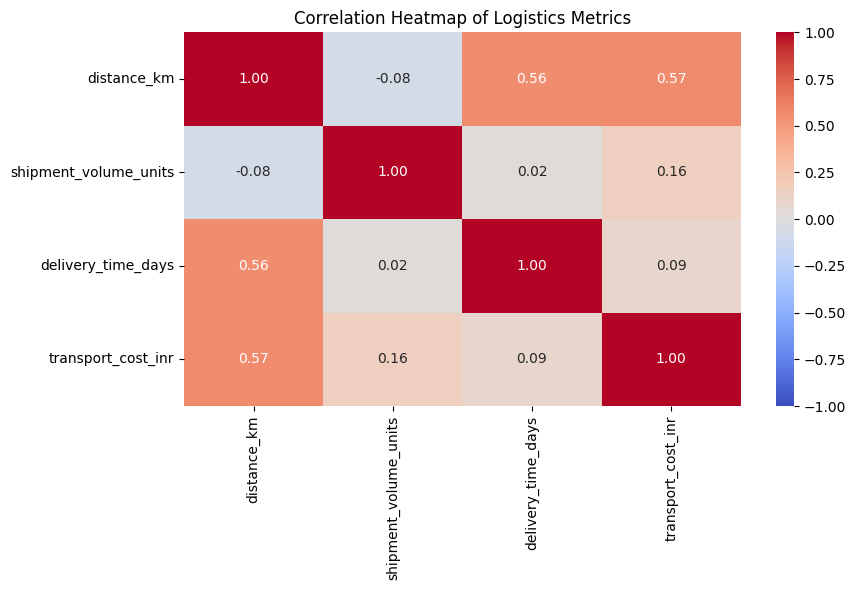

In [23]:
metrics = [
    "distance_km",
    "shipment_volume_units",
    "delivery_time_days",
    "transport_cost_inr"
]

correlation_matrix = df[metrics].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Logistics Metrics")
plt.tight_layout()
plt.show()

Average Delivery Time By Transport Mode

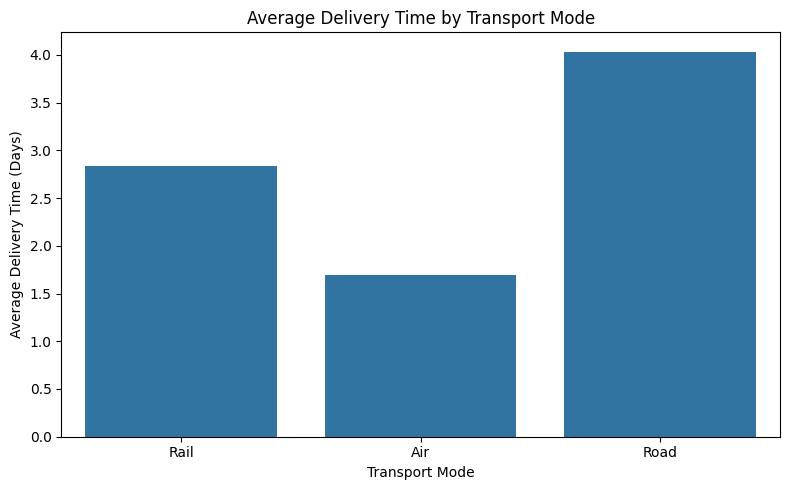

In [24]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="transport_mode",
    y="delivery_time_days",
    errorbar=None
)

plt.title("Average Delivery Time by Transport Mode")
plt.xlabel("Transport Mode")
plt.ylabel("Average Delivery Time (Days)")

plt.tight_layout()
plt.show()

Average Transportation Cost By Region

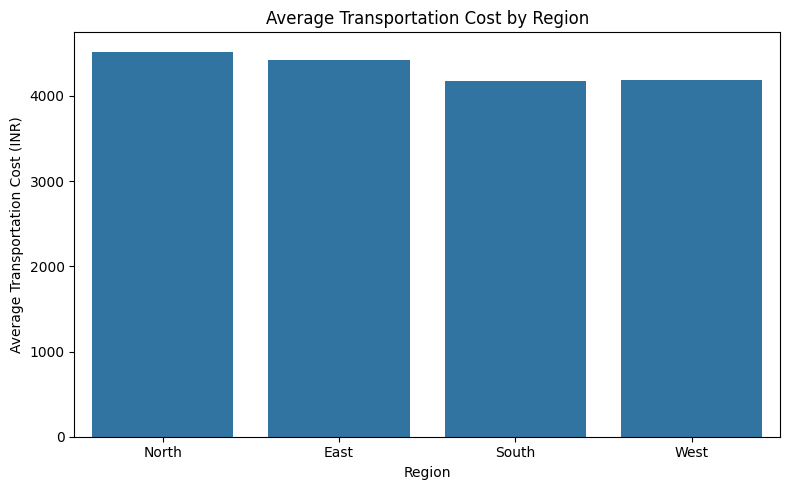

In [25]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="region",
    y="transport_cost_inr",
    errorbar=None
)

plt.title("Average Transportation Cost by Region")
plt.xlabel("Region")
plt.ylabel("Average Transportation Cost (INR)")

plt.tight_layout()
plt.show()

In [26]:
print("Week-3 is Succesfully Completed")

Week-3 is Succesfully Completed
